# 02. Preprocessing and features

**Purpose.** Show every transformation between a raw spreadsheet cell and the model's feature matrix, and why each one exists.

The pipeline has two layers, and **both run identically in training and in the upload path** of the dashboard:

1. **Validation layer** (`ledgerclf.io`, `ledgerclf.schema`, `ledgerclf.values`): reads any Excel or CSV file, finds the header, maps columns, and cleans each cell. It never imputes and never drops a non-empty row; problems become flagged issues.
2. **Feature pipeline** (`ledgerclf.features.build_feature_pipeline`): one scikit-learn `ColumnTransformer` that is **fitted inside each cross-validation fold** and, for the final model, on the training portion only. The same fitted object transforms uploads, so training and inference cannot drift apart.

Tables come from `python -m ledgerclf eda` (`reports/preprocessing/`); the live demo below calls the package functions directly.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from _style import INK_SECONDARY, apply_style, report
from IPython.display import display

from ledgerclf.config import get_settings
from ledgerclf.io import read_table
from ledgerclf.schema import coerce_values, resolve_columns

apply_style()
pd.set_option("display.max_colwidth", 70)
settings = get_settings()

## 1. The validation layer on a messy file

A grader's file will not look like the training file. The cell below builds a deliberately messy CSV: semicolon delimiter, a title row above lowercase headers, currency strings, a European number, a US-style date, an Excel serial date, invisible characters, a lowercase document flag, an empty line, and an unreadable amount. It then runs the exact functions the upload path uses.

In [2]:
messy = (
    "Ledger export, December 2018\n"
    "col1;col2;col3;col4;col5;col6;col7\n"
    "Word16 Word17 Word18 Word7;4.80P+11;$1,680.00;Word61;08/31/2018;Word563 Word564 Word9 Word26;nodoc\n"
    "Word19\u00a0Word20 Word21 Word22 Word23 Word5;10719;(617.60);Word562;43343;Word563 Word575;NoDoc\n"
    ";;;;;;\n"
    "Word324 Word4;W-1;1.234,56;;2018-10-31 00:00:00;Word563;DOC1\n"
    "Word8 Word9 Word10 Word11 Word5;65975;n/a;Word775\u200b Word776;Oct 2018;Word563 Word564 Word9 Word26;NoDoc\n"
).encode("utf-8")

raw, info, read_issues = read_table(messy, "messy_export.csv", settings.limits)
resolved, mapping, resolve_issues = resolve_columns(raw, settings.limits)
clean, coerce_issues = coerce_values(resolved, settings.limits)
print(
    f"Detected format: {info.detected_format}, delimiter {info.delimiter!r}, header on line {info.header_row_index + 1}"
)
display(resolved)
display(
    clean[
        [
            "source_row",
            "Col1",
            "Col3",
            "amount",
            "Col4",
            "Col5",
            "period",
            "Col7",
            "amount_was_missing",
        ]
    ]
)
pd.DataFrame([i.to_dict() for i in [*read_issues, *resolve_issues, *coerce_issues]])[
    ["severity", "code", "message"]
]

Detected format: csv, delimiter ';', header on line 2


,source_row,Col1,Col2,Col3,Col4,Col5,Col6,Col7
0,3,Word16 Word17 Word18 Word7,4.80P+11,"$1,680.00",Word61,08/31/2018,Word563 Word564 Word9 Word26,nodoc
1,4,Word19 Word20 Word21 Word22 Word23 Word5,10719,(617.60),Word562,43343,Word563 Word575,NoDoc
2,5,,,,,,,
3,6,Word324 Word4,W-1,"1.234,56",,2018-10-31 00:00:00,Word563,DOC1
4,7,Word8 Word9 Word10 Word11 Word5,65975,n/a,Word775​ Word776,Oct 2018,Word563 Word564 Word9 Word26,NoDoc


,source_row,Col1,Col3,amount,Col4,Col5,period,Col7,amount_was_missing
0,3,Word16 Word17 Word18 Word7,1680.00,1680.00,Word61,2018-08,24224.0,NoDoc,False
1,4,Word19 Word20 Word21 Word22 Word23 Word5,-617.60,-617.60,Word562,2018-08,24224.0,NoDoc,False
2,6,Word324 Word4,1234.56,1234.56,None,2018-10,24226.0,Doc1,False
3,7,Word8 Word9 Word10 Word11 Word5,None,NaN,Word775 Word776,2018-10,24226.0,NoDoc,True


,severity,code,message
0,WARNING,EMPTY_ROWS_DROPPED,Dropped 1 empty row(s). Spreadsheet rows: 5.
1,WARNING,AMOUNT_UNPARSEABLE,1 amount(s) in Col3 were missing or unreadable and were replaced b...


**What happened.**

- The delimiter (`;`) and the header row (line 2, under a title line) were detected; lowercase `col1` mapped to `Col1`.
- `$1,680.00` became 1680.0, `(617.60)` became -617.6 (accounting negative), `1.234,56` became 1234.56 (European format).
- `08/31/2018`, the Excel serial `43343`, `2018-10-31 00:00:00`, and `Oct 2018` all became monthly periods (`YYYY-MM`).
- A non-breaking space and a zero-width space vanished from the text; `nodoc` and `DOC1` became the canonical `NoDoc` and `Doc1`.
- The empty line was dropped with a warning that names its spreadsheet row; every other row kept its true `source_row`.
- `n/a` in the amount became missing with a warning. The **feature pipeline** fills it with the training median and the row is flagged; the row still gets a prediction.

The full catalog of 79 edge cases (file formats, encodings, header variants, value formats, labels, environment) has a test each in `tests/edge_cases/`; an adversarial review added 35 more in `tests/adversarial/`.

## 2. Before and after: five training rows

Each input column at three stages: the raw cell from the Excel file, the cleaned value after validation, and what the feature pipeline sees.

In [3]:
samples = report("preprocessing/before_after_samples.csv")
samples[samples["row_id"] == samples["row_id"].iloc[0]]

,row_id,column,raw_value,cleaned_value,model_input
0,0,Col1,Word1 Word2 Word3 Word4 Word5,Word1 Word2 Word3 Word4 Word5,word1 word2 word3 word4 word5
1,0,Col2,44912133,44912133,not used by the model (D04)
2,0,Col3,3575,3575.00,"signed_log=8.1820, negative=0"
3,0,Col4,Word771 Word772,Word771 Word772,word771 word772
4,0,Col5,2018-08-31 00:00:00,2018-08,"period index 24224 (2018-08), then standardized"
5,0,Col6,Word560 Word561 Word366 Word562,Word560 Word561 Word366 Word562,word560 word561 word366 word562
6,0,Col7,Doc1,Doc1,doc1


In [4]:
samples.pivot(index="row_id", columns="column", values="model_input")

column,Col1,Col2,Col3,Col4,Col5,Col6,Col7
row_id,,,,,,,
0,word1 word2 word3 word4 word5,not used by the model (D04),"signed_log=8.1820, negative=0",word771 word772,"period index 24224 (2018-08), then standardized",word560 word561 word366 word562,doc1
1477,word85 word86 word87 word5 word88 word16 word17 word3 word7,not used by the model (D04),"signed_log=4.6634, negative=0",word944 word945,"period index 24216 (2017-12), then standardized",word563 word580 word581 word232,nodoc
2949,word48 word3 word4 word5,not used by the model (D04),"signed_log=6.4473, negative=0",word780 word877,"period index 24218 (2018-02), then standardized",word563 word564 word9 word26,nodoc
4417,word160 word161 word61 word45 word39,not used by the model (D04),"signed_log=3.9318, negative=0",word61,"period index 24226 (2018-10), then standardized",word563 word564 word9 word26,nodoc
5898,word40 word41 word4 word5,not used by the model (D04),"signed_log=7.5071, negative=0",word802 word278 word1242 word803,"period index 24223 (2018-07), then standardized",word567 word582 word580 word202 word545,doc1


**Takeaway.** Text is lowercased (`Word563` and `word563` are one token) and a missing description becomes the token `__missing__`, which is itself informative. The amount enters as a signed log plus two flags; the date enters as a period index clipped to the training range; Col2 is not used.

## 3. The feature pipeline, transformer by transformer

In [5]:
catalog = report("preprocessing/transformer_catalog.json")
pd.DataFrame(
    [
        {
            "transformer": t["name"],
            "input": ", ".join(t["columns"]) if isinstance(t["columns"], list) else t["columns"],
            "steps": " -> ".join(s["class"] for s in t["steps"]),
            "why": t["reason"],
            "decision": t["decision"],
        }
        for t in catalog["transformers"]
    ]
)

,transformer,input,steps,why,decision
0,col1_tokens,Col1,TextNormalizer -> TfidfVectorizer,Vendor tokens carry identity; one vectorizer per column keeps role...,D05
1,col1_value,Col1,TextNormalizer -> OneHotEncoder,Whole vendor names recur; values seen once fold into an infrequent...,D05
2,col4_tokens,Col4,TextNormalizer -> TfidfVectorizer,Line descriptions are the strongest single signal (ablation: -4 po...,D05
3,col6_tokens,Col6,TextNormalizer -> TfidfVectorizer,Account tokens separate classes within a vendor.,D05
4,col6_value,Col6,TextNormalizer -> OneHotEncoder,"Whole account names, infrequent values bucketed.",D05
5,pair,"Col1, Col6",TextNormalizer -> ColumnConcat -> OneHotEncoder,Vendor-account pairs resolve vendors split across classes.,D05
6,col7,Col7,TextNormalizer -> OneHotEncoder,Document flag; Doc3 holds most Category_4 rows.,D05
7,amount,amount,TrainingMedianImputer -> SignedLogAmount -> StandardScaler,Signed log keeps credits negative and tames an 8.8 million maximum.,D07
8,amount_flags,amount,TrainingMedianImputer -> AmountFlags,"Negative and round amounts mark rare classes (Category_5, Category...",D07
9,period,period,TrainingMedianImputer -> PeriodEncoder -> StandardScaler,"Monthly period index, clipped to the training range to stop extrap...",D08


Key parameter choices (all in `ledgerclf/config.py`):

| Step | Choice | Why |
|---|---|---|
| `TfidfVectorizer` per text column | token pattern `\S+`, unigrams, sublinear TF | Tokens are atomic IDs (`Word563`); the same token means different things in different columns; bigrams added nothing in exploration (D05) |
| `OneHotEncoder` on whole Col1, Col6, and the Col1-Col6 pair | `min_frequency=2`, unknowns to the infrequent bucket | Recurring vendors, accounts, and pairs get their own weight; one-off values share a bucket, so an unseen vendor at inference maps to a known feature instead of nothing |
| `TrainingMedianImputer` | median of the training fold | Fitted inside the pipeline, so cross-validation never leaks a statistic from the test fold |
| `SignedLogAmount` + `StandardScaler` | `sign(x) * log1p(|x|)` | 8.8 million maximum, -269,112 minimum; credits must stay negative (D07) |
| `AmountFlags` | negative, multiple of 10 | Only Category_5 signal; round values recur in rare classes (D07) |
| `PeriodEncoder` + `StandardScaler` | `year*12 + month`, clipped to training range | Linear models must not extrapolate to 2030 (D08) |

No scaling is applied to TF-IDF or one-hot blocks: they are already on a 0 to 1 scale, and the matrix stays sparse.

## 4. The feature space

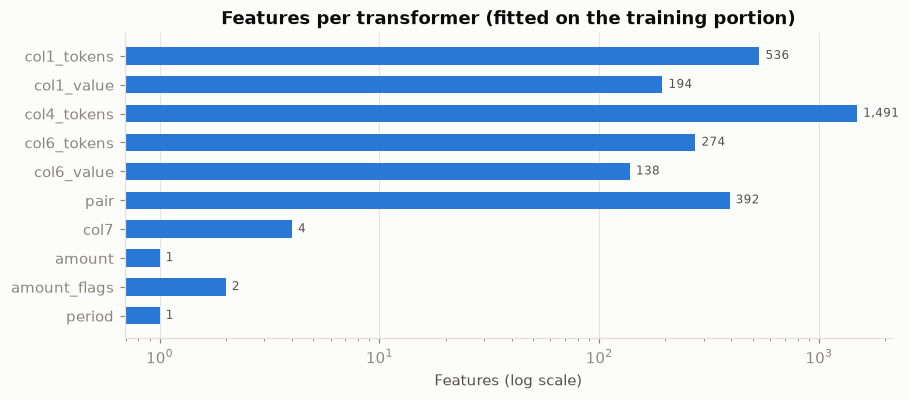

,transformer,group,features,rows_with_nonzero_share,mean_nonzero_per_row
0,col1_tokens,Col1,536,1.000000,3.959126
1,col1_value,Col1,194,1.000000,1.000000
2,col4_tokens,Col4,1491,1.000000,2.746845
3,col6_tokens,Col6,274,1.000000,3.756828
4,col6_value,Col6,138,1.000000,1.000000
5,pair,Col1+Col6,392,1.000000,1.000000
6,col7,Col7,4,1.000000,1.000000
7,amount,Col3,1,1.000000,1.000000
8,amount_flags,Col3,2,0.370691,0.371445
9,period,Col5,1,1.000000,1.000000


In [6]:
space = report("preprocessing/feature_space_summary.csv")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(space["transformer"][::-1], space["features"][::-1], color="#2a78d6", height=0.6)
ax.set_xscale("log")
ax.set_xlabel("Features (log scale)")
ax.set_title("Features per transformer (fitted on the training portion)")
for y, value in enumerate(space["features"][::-1]):
    ax.annotate(
        f"{value:,}",
        (value, y),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
        color=INK_SECONDARY,
    )
ax.grid(axis="y", visible=False)
plt.show()
space

In [7]:
snapshots = report("preprocessing/stage_snapshots.json")
pd.DataFrame(
    {
        stage: {k: v for k, v in details.items() if isinstance(v, int | float | str)}
        for stage, details in snapshots.items()
    }
).T

,rows,scope,density,features,format,stored_values
coerced,5309,training portion,NaN,NaN,NaN,NaN
matrix,5309,training portion,0.00555,3033,scipy CSR (sparse),89373
resolved,5309,"training portion, original cells",NaN,NaN,NaN,NaN


**Takeaway.** 5,309 training rows become a **3,033-column sparse matrix** with about 17 non-zero values per row (density 0.55%). Half of the columns come from Col4 descriptions. Every row has text features; 37% of rows set at least one amount flag. The matrix is never densified: logistic regression and LightGBM both consume the sparse CSR matrix directly.

**Every output feature maps to exactly one source group** (Col1, Col1+Col6 pair, Col3, Col4, Col5, Col6, Col7); a unit test checks this. The grouping is what lets the explanation agent say *"the account contributed +1.4 toward Category_2"* with exact numbers.

Next: `03_modeling.ipynb` compares models on this matrix with grouped cross-validation.